In [1]:
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from aeon.visualisation import create_multi_comparison_matrix

In [2]:
def load_tsb_ad(
    mode: Literal["multivariate", "univariate"], return_characteristics: bool = False
) -> (pd.DataFrame, pd.DataFrame | None):
    mode_ = "uni" if mode == "univariate" else "multi"
    tsb_ad_raw_ = pd.read_csv(
        f"../results/TSB-AD/{mode_}_mergedTable_VUS-PR.csv", index_col="file"
    )
    tsb_ad_characteristics_cols_ = [
        "ts_len",
        "anomaly_len",
        "num_anomaly",
        "avg_anomaly_len",
        "anomaly_ratio",
        "point_anomaly",
        "seq_anomaly",
    ]
    tsb_ad_characteristics_ = tsb_ad_raw_[tsb_ad_characteristics_cols_]
    tsb_ad_ = tsb_ad_raw_.drop(columns=tsb_ad_characteristics_cols_)
    if return_characteristics:
        return tsb_ad_, tsb_ad_characteristics_
    else:
        return tsb_ad_


def load_results(
    method: str,
    mode: Literal["multivariate", "univariate"],
    return_runtime: bool = False,
) -> pd.DataFrame:
    results = pd.read_csv(f"../results/benchmarks/{method}-{mode}.csv")
    results = results.rename(columns={"VolumeUnderPR_TSBAD()": method})
    if return_runtime:
        return results[["file", "Runtime [s]"]].set_index("file")
    else:
        return results[["file", method]].set_index("file")


def load_with_tsb_ad(
    method: str, mode: Literal["multivariate", "univariate"]
) -> pd.DataFrame:
    tsb_ad_ = load_tsb_ad(mode=mode, return_characteristics=False)
    results_ = (
        load_results(method=method, mode=mode, return_runtime=False)
        .groupby("file")
        .mean()
    )
    return tsb_ad_.join(results_)

In [13]:
load_results("HydraAD", "univariate").describe()

,HydraAD
count,10500.000000
mean,0.548208
std,0.358937
min,0.001259
25%,0.166961
50%,0.614393
75%,0.899746
max,1.000000


In [16]:
load_results("HydraAD", "multivariate").describe()

,HydraAD
count,5400.000000
mean,0.380040
std,0.361949
min,0.006360
25%,0.042977
50%,0.172024
75%,0.790278
max,0.998916


In [24]:
load_tsb_ad("univariate").describe()[["POLY", "Sub-PCA"]]

Sub-IForest           0.082684
IForest               0.174682
Sub-LOF               0.145694
LOF                   0.084558
POLY                  0.335194
MatrixProfile         0.256815
KShapeAD              0.233305
SAND                  0.196184
Series2Graph          0.303674
SR                    0.196313
Sub-PCA               0.346938
Sub-HBOS              0.086475
Sub-OCSVM             0.104982
Sub-MCD               0.128676
Sub-KNN               0.260133
KMeansAD              0.213234
AutoEncoder           0.141090
CNN                   0.221167
LSTMAD                0.160441
TranAD                0.082341
AnomalyTransformer    0.052458
OmniAnomaly           0.099191
USAD                  0.173943
Donut                 0.091377
TimesNet              0.134243
FITS                  0.124747
OFA                   0.114091
Lag-Llama             0.124212
Chronos               0.137111
TimesFM               0.159780
MOMENT (ZS)           0.284257
MOMENT (FT)           0.283752
Name: 50

In [27]:
load_tsb_ad("multivariate").describe()[["CNN"]]

,CNN
count,180.000000
mean,0.312985
std,0.333477
min,0.003572
25%,0.050093
50%,0.173076
75%,0.463838
max,0.999693


## Boxplots with the average VUS-PR across complete benchmark set

In [3]:
def plot(
    df: pd.DataFrame,
    ax: plt.Axes = None,
    figsize=(20, 4),
    title: str = "",
    nb_methods: int = None,
    highlight_method: list[str] = None,
    x_label_rotation: int = 90,
) -> plt.Figure:
    sns.set_theme()
    mean_df = pd.DataFrame()
    mean_df["VUS_PR_Rank"] = df.mean().rank(ascending=False)
    sorted_mean_df = mean_df.sort_values(by="VUS_PR_Rank", ascending=True)

    if nb_methods is None:
        nb_methods = sorted_mean_df.shape[0]
    rank_list = sorted_mean_df.index[:nb_methods]

    palette_kwarg = {}
    if highlight_method is not None and len(highlight_method) > 0:
        color_default = "#E0E0E0"  # Light Grey for standard
        color_highlight = (
            "#1f77b4"  # Distinct Blue for highlight (or use 'red', 'orange', etc.)
        )
        palette_kwarg["palette"] = [
            color_highlight if method in highlight_method else color_default
            for method in rank_list
        ]

    if ax is None:
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(1, 1, 1)
    else:
        fig = ax.figure

    sns.boxplot(
        ax=ax,
        data=df[rank_list],
        showfliers=False,
        meanprops=dict(color="k", linestyle="--"),
        showmeans=True,
        meanline=True,
        **palette_kwarg,
    )
    ax.set_title(title, fontsize=16)
    ax.set_xticks(
        ticks=range(len(rank_list)),
        labels=rank_list,
        rotation=x_label_rotation,
        fontsize=10,
    )
    ax.set_ylabel("VUS-PR", fontsize=12)
    fig.tight_layout()

    return fig

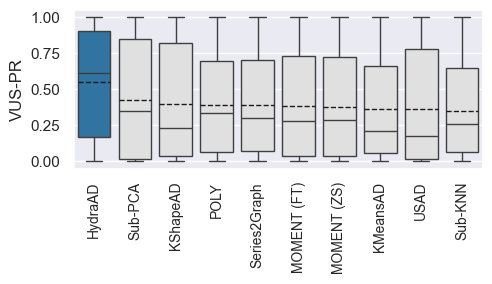

In [4]:
fig = plot(
    load_with_tsb_ad("HydraAD", mode="univariate"),
    highlight_method=["HydraAD"],
    nb_methods=10,
    # title=f"TSB-AD-U",
    figsize=(5, 3),
)
# fig.axes[0].tick_params(axis='x', labelrotation=0)
fig.savefig("figures/fig-tsb-ad-u.png", bbox_inches="tight")

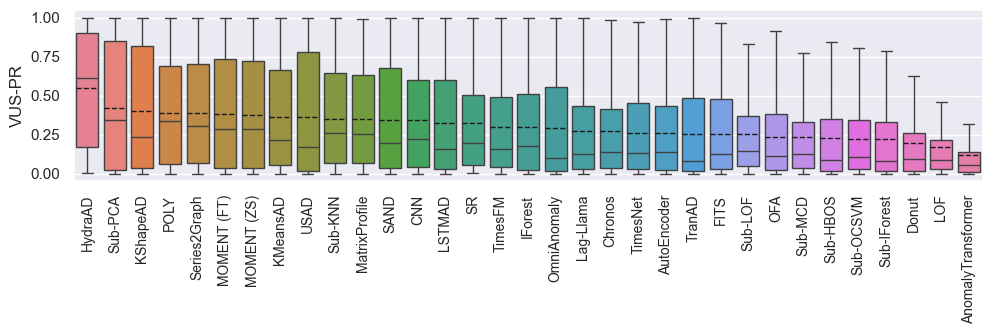

In [5]:
fig = plot(load_with_tsb_ad("HydraAD", mode="univariate"), figsize=(10, 3.5))
fig.savefig("figures/fig-tsb-ad-u-full.png", bbox_inches="tight")

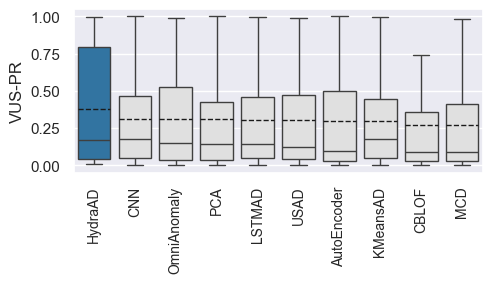

In [6]:
fig = plot(
    load_with_tsb_ad("HydraAD", mode="multivariate"),
    highlight_method=["HydraAD"],
    nb_methods=10,
    # title=f"TSB-AD-M",
    figsize=(5, 3),
)
fig.savefig("figures/fig-tsb-ad-m.png", bbox_inches="tight")

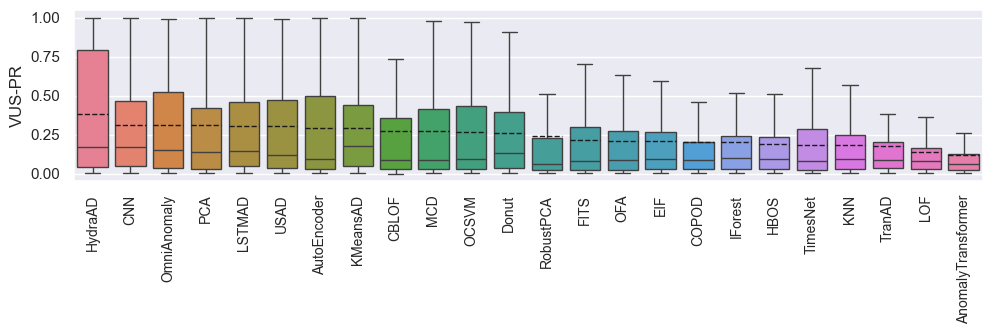

In [7]:
fig = plot(
    load_with_tsb_ad("HydraAD", mode="multivariate"),
    # title=f"TSB-AD-M",
    figsize=(10, 3.5),
)
fig.savefig("figures/fig-tsb-ad-m-full.png", bbox_inches="tight")

## Multi-comparison matrix

In [8]:
def multi_comparison_matrix_plot(
    df: pd.DataFrame,
    title: str = "",
    nb_methods: int = None,
    in_rows: list[str] = None,
    precision: int = 4,
    figsize="auto",
) -> plt.Figure:
    if nb_methods is not None:
        df = df[df.mean().sort_values(ascending=False).index[:nb_methods]]
    fig = create_multi_comparison_matrix(
        df,
        fig_size=figsize,
        precision=precision,
        row_comparates=in_rows,
        excluded_col_comparates=in_rows,
        include_legend=False,
        colormap=None,
    )
    fig.suptitle(title, fontsize=16)
    fig.tight_layout()
    return fig

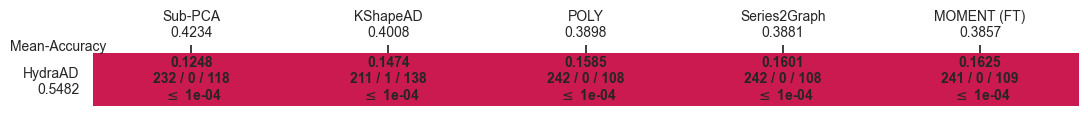

In [9]:
multi_comparison_matrix_plot(
    load_with_tsb_ad("HydraAD", mode="univariate"),
    nb_methods=6,
    in_rows=["HydraAD"],
    figsize=(11, 1.5),
    precision=4,
);

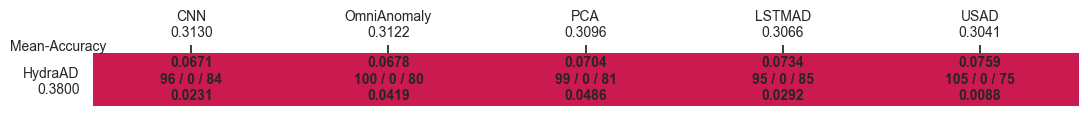

In [10]:
multi_comparison_matrix_plot(
    load_with_tsb_ad("HydraAD", mode="multivariate"),
    nb_methods=6,
    in_rows=["HydraAD"],
    figsize=(11, 1.5),
    precision=4,
);

## Per domain

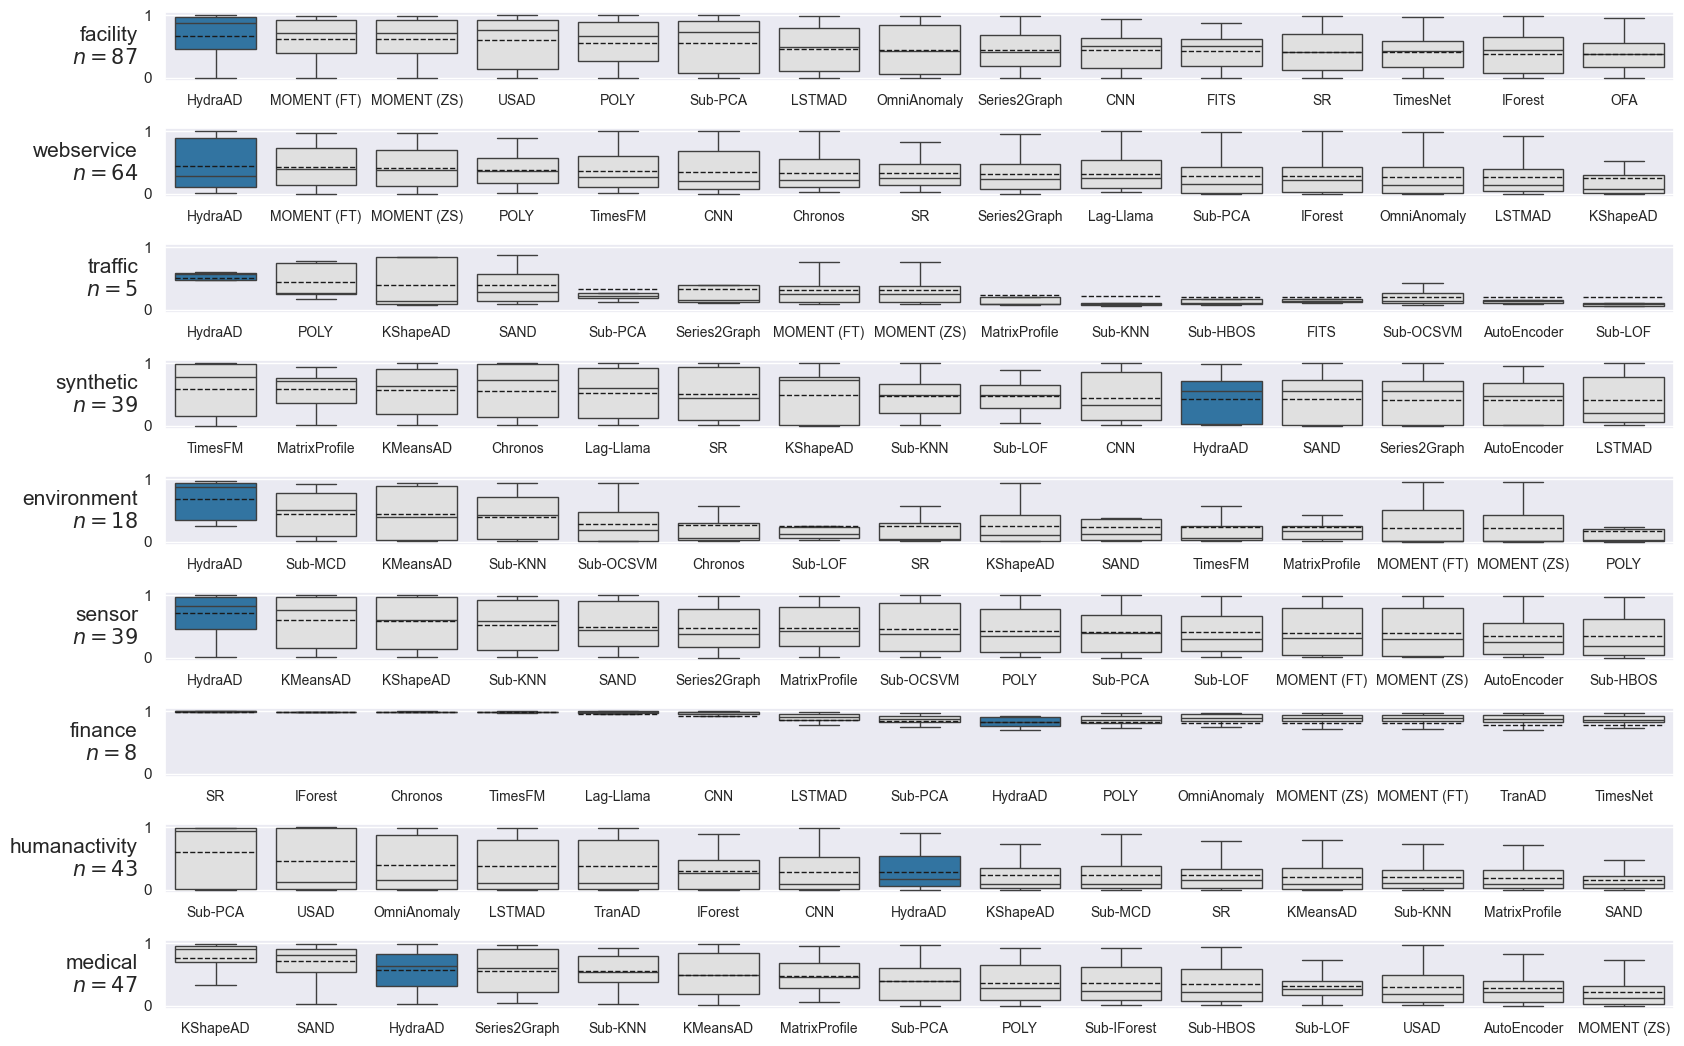

In [36]:
def get_domain(dataset_name: str) -> str:
    return dataset_name.split("_")[4].lower()


def plot_in_function_of_domain(
    df: pd.DataFrame,
    figsize=(20, 3),
    title: str = "",
    nb_methods: int = None,
    min_nb_samples_per_domain: int = 5,
    highlight_method: list[str] = None,
    x_label_rotation: int = 90,
):
    tmp = df.index.map(get_domain)
    domains = [
        domain
        for domain in tmp.unique()
        if (tmp == domain).sum() >= min_nb_samples_per_domain
    ]
    n_domains = len(domains)

    fig, axes = plt.subplots(
        n_domains, 1, figsize=(figsize[0], figsize[1] * n_domains), sharey="all"
    )
    for i, domain in enumerate(domains):
        ax = axes[i] if n_domains > 1 else axes
        domain_df = df[tmp == domain]
        plot(
            domain_df,
            ax=ax,
            figsize=(figsize[0], figsize[1]),
            nb_methods=nb_methods,
            highlight_method=highlight_method,
            # title=f"{domain} ($n={domain_df.shape[0]}$)",
            x_label_rotation=x_label_rotation,
        )
        ax.set_ylabel(
            f"{domain}\n$n={domain_df.shape[0]}$",
            rotation=0,
            va="center",
            ha="right",
            y=0.5,
            fontsize=15,
        )

    fig.suptitle(title, fontsize=18)
    fig.tight_layout()

    return fig

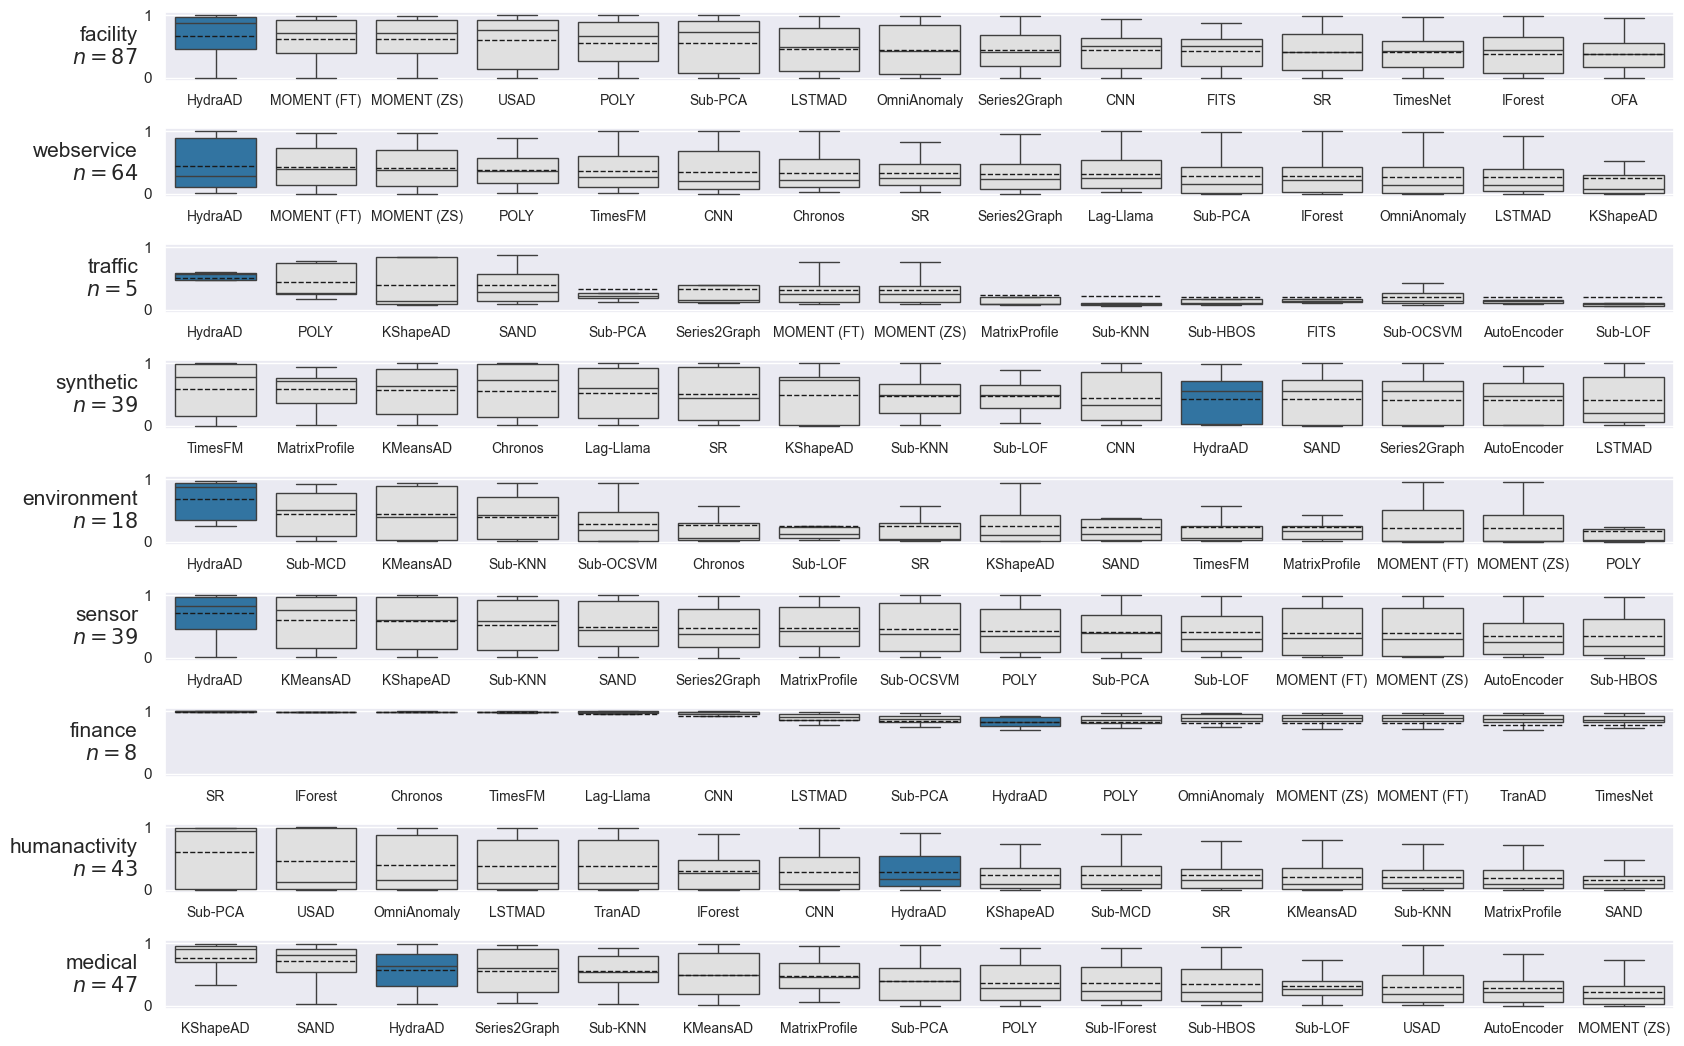

In [37]:
fig = plot_in_function_of_domain(
    load_with_tsb_ad("HydraAD", mode="univariate"),
    highlight_method=["HydraAD"],
    nb_methods=15,
    x_label_rotation=0,
    # min_nb_samples_per_domain=25,
    figsize=(17, 1.2),
)
fig.savefig("figures/fig-tsb-ad-u-domain.png", bbox_inches="tight")